# Notebook 01: Data Exploration & CIE Lab Color Space

Welcome to the first step of building an **Image Colorization** model!

### Why CIE Lab instead of RGB?
- In **RGB**, every pixel has Red, Green, and Blue mixed together. A black-and-white image loses all color information across all 3 channels.
- In **CIE Lab**:
  - **$L$ (Lightness)**: Represents the black & white brightness ($0 = \text{black}, 100 = \text{white}$). This is our **INPUT** to the model.
  - **$a$**: Green $\leftrightarrow$ Red (Negative is Green, Positive is Red).
  - **$b$**: Blue $\leftrightarrow$ Yellow (Negative is Blue, Positive is Yellow).
  - **$a$ and $b$ together**: Represent the **COLORS**. This is our model's **TARGET**!

By predicting only **2 channels ($a, b$)** instead of 3, the model's job is simpler, sharper, and never degrades the original resolution of the grayscale photo.

### 1. Check GPU & Libraries

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage import color
import torch

# Check if GPU is ready
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


### 2. Verify Dataset Folders and Count Images

In [2]:
train_dir = os.path.join("..", "data", "raw", "train")
val_dir = os.path.join("..", "data", "raw", "val")

train_images = [os.path.join(train_dir, f) for f in os.listdir(train_dir) if f.endswith((".jpg", ".png"))]
val_images = [os.path.join(val_dir, f) for f in os.listdir(val_dir) if f.endswith((".jpg", ".png"))]

print(f"Found {len(train_images)} training images in data/raw/train")
print(f"Found {len(val_images)} validation images in data/raw/val")

Found 2000 training images in data/raw/train
Found 200 validation images in data/raw/val


### 3. Load a Random Image & Convert RGB $\to$ CIE Lab

In [3]:
# Pick a random image
random_img_path = random.choice(train_images)

# Load and resize to standard 256x256
img_pil = Image.open(random_img_path).convert("RGB").resize((256, 256))
img_rgb = np.array(img_pil)

# Convert from RGB to CIE Lab
img_lab = color.rgb2lab(img_rgb)

# Separate the 3 channels
L = img_lab[:, :, 0]   # Lightness: 0 to 100
a = img_lab[:, :, 1]   # Green to Red: -128 to +127
b = img_lab[:, :, 2]   # Blue to Yellow: -128 to +127

print("RGB image shape:", img_rgb.shape, "| Value range:", img_rgb.min(), "to", img_rgb.max())
print("L channel range :", round(L.min(), 1), "to", round(L.max(), 1), "(Lightness: Input)")
print("a channel range :", round(a.min(), 1), "to", round(a.max(), 1), "(Green-Red: Target)")
print("b channel range :", round(b.min(), 1), "to", round(b.max(), 1), "(Blue-Yellow: Target)")

RGB image shape: (256, 256, 3) | Value range: 0 to 255
L channel range : 0.0 to 100.0 (Lightness: Input)
a channel range : -25.5 to 58.6 (Green-Red: Target)
b channel range : -14.9 to 34.2 (Blue-Yellow: Target)


### 4. Visualize the Channels Side-by-Side
- **Original RGB**: Full color image.
- **L Channel**: The exact grayscale image our model will be given.
- **a Channel**: Heatmap of Green vs Red hues.
- **b Channel**: Heatmap of Blue vs Yellow hues.

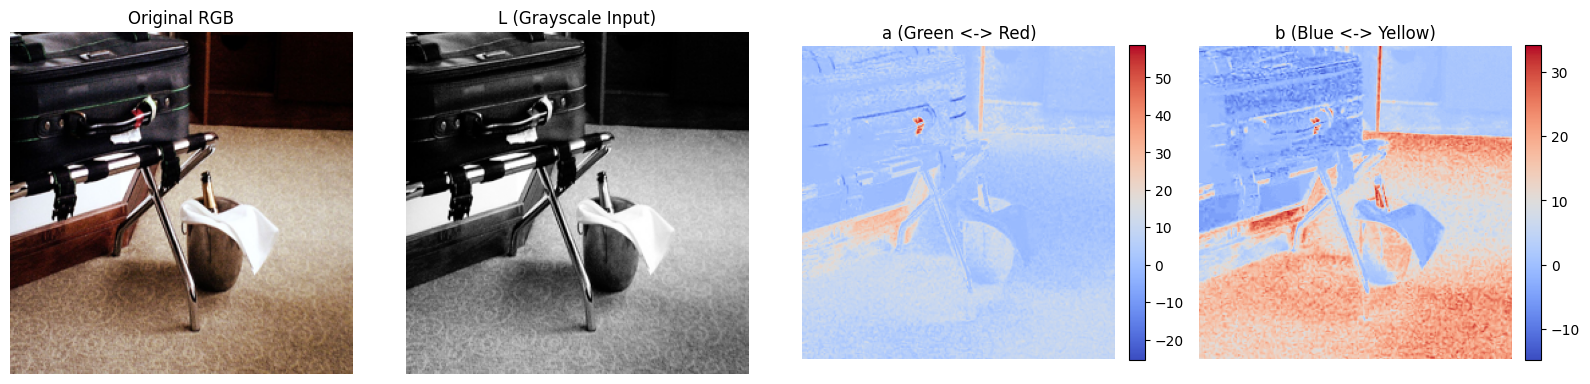

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(img_rgb)
axes[0].set_title("Original RGB")
axes[0].axis("off")

axes[1].imshow(L, cmap="gray")
axes[1].set_title("L (Grayscale Input)")
axes[1].axis("off")

im_a = axes[2].imshow(a, cmap="coolwarm")
axes[2].set_title("a (Green <-> Red)")
axes[2].axis("off")
plt.colorbar(im_a, ax=axes[2], fraction=0.046, pad=0.04)

im_b = axes[3].imshow(b, cmap="coolwarm")
axes[3].set_title("b (Blue <-> Yellow)")
axes[3].axis("off")
plt.colorbar(im_b, ax=axes[3], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

### 5. Normalization & Reconstruction Helper Functions

Neural networks train best when values are scaled to **$[-1, 1]$**:
- $L \in [0, 100] \implies \frac{L}{50} - 1 \in [-1, 1]$
- $ab \in [-128, 127] \implies \frac{ab}{128} \in [-1, 1]$

Let's write two simple helper functions to convert back and forth:

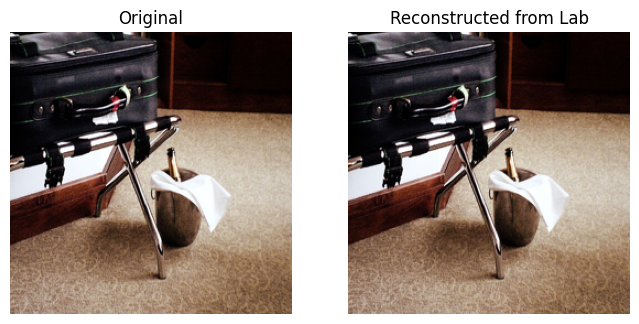

In [5]:
def lab_to_rgb(L_tensor, ab_tensor):
    """
    Takes normalized L ([-1, 1]) and normalized ab ([-1, 1]),
    denormalizes them, and returns an RGB image.
    """
    # Denormalize L to [0, 100] and ab to [-128, 128]
    L_denorm = (L_tensor + 1.0) * 50.0
    ab_denorm = ab_tensor * 128.0
    
    # Combine L and ab into a 3-channel (H, W, 3) array
    lab = np.zeros((256, 256, 3), dtype=np.float64)
    lab[:, :, 0] = L_denorm
    lab[:, :, 1:] = ab_denorm
    
    # Convert to RGB and clip to valid [0, 1] range
    rgb = color.lab2rgb(lab)
    rgb = np.clip(rgb, 0.0, 1.0)
    return rgb

# Test our helper function with the current image
L_norm = (L / 50.0) - 1.0
ab_norm = np.stack([a, b], axis=-1) / 128.0

reconstructed_rgb = lab_to_rgb(L_norm, ab_norm)

# Display side-by-side to verify reconstruction is identical to original
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img_rgb)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(reconstructed_rgb)
axes[1].set_title("Reconstructed from Lab")
axes[1].axis("off")
plt.show()

### 6. Preview Sample Dataset Images (Grayscale Input vs Color Truth)
Here is a preview of 4 random images from your dataset showing:
- Top row: The grayscale input the model will receive.
- Bottom row: The full color ground truth the model will learn to predict.

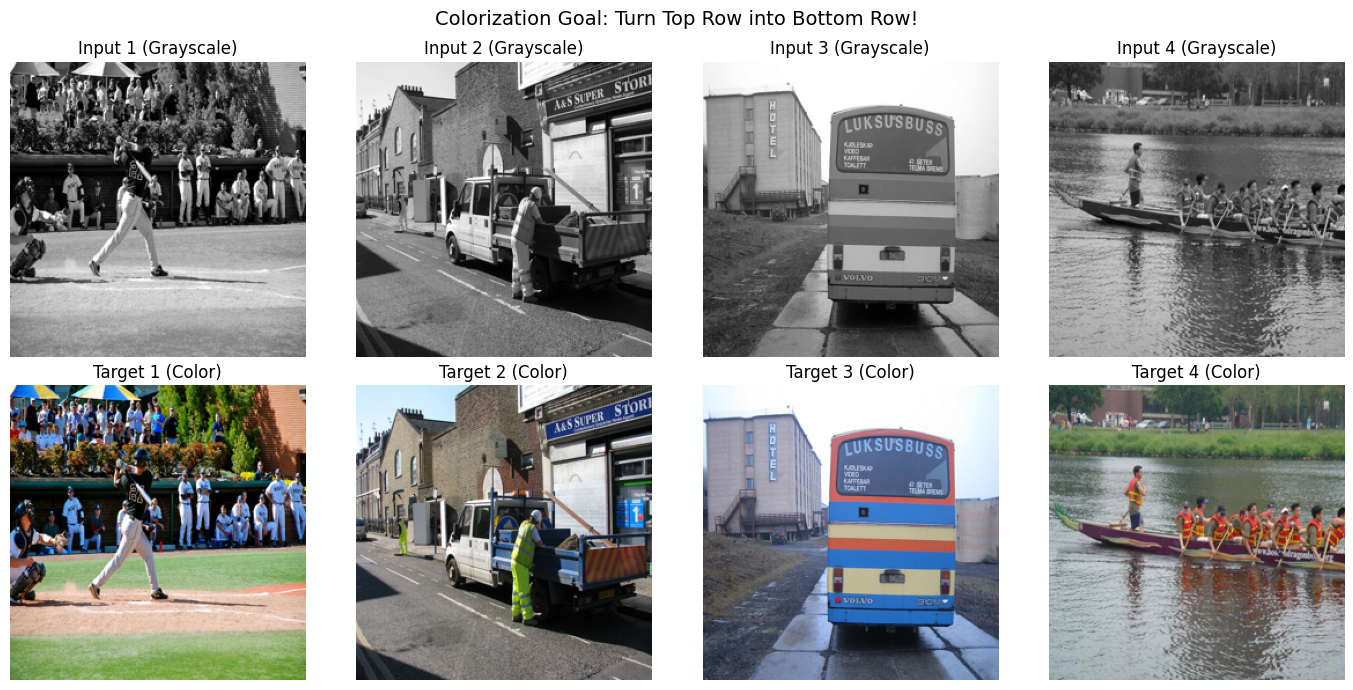

In [6]:
sample_paths = random.sample(train_images, 4)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, p in enumerate(sample_paths):
    im = Image.open(p).convert("RGB").resize((256, 256))
    im_gray = im.convert("L")
    
    # Top row: Grayscale input
    axes[0, i].imshow(im_gray, cmap="gray")
    axes[0, i].set_title(f"Input {i+1} (Grayscale)")
    axes[0, i].axis("off")
    
    # Bottom row: Ground truth color
    axes[1, i].imshow(im)
    axes[1, i].set_title(f"Target {i+1} (Color)")
    axes[1, i].axis("off")

plt.suptitle("Colorization Goal: Turn Top Row into Bottom Row!", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

### Summary & Next Step
In this notebook, we learned:
1. Our model takes **1 channel ($L$, grayscale)** and outputs **2 channels ($a, b$, color)**.
2. Values are normalized between $[-1, 1]$ for stable neural network training.
3. We have verified **2,000 training images** and **200 validation images** ready in `data/raw/`.

👉 **Next Notebook:** `02_dataset_and_dataloader.ipynb` where we create the PyTorch `Dataset` and `DataLoader` with augmentations.